In [1]:
## -*- coding: utf-8 -*-
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
from math import *
import matplotlib.cm as cm
import warnings
import pandas as pd
from pandas import DataFrame
from numba import njit, prange
import itertools
from scipy.stats import chi2
import scipy.stats as stats
from matplotlib import colors as mcolors
warnings.filterwarnings("ignore")

%matplotlib inline

In [2]:
### Define functions

'''
- make_fasta: creates a FASTA file from a list of sequences.
    - seqs: list of sequences to include in the FASTA file.
    - Name: name of the FASTA file to create (without extension).
    - key: type of sequences ('RNA' or 'DNA') to determine whether to replace 'T' with 'U'.

- permutation_test: performs a permutation test to compare the average values of two groups of elements in a matrix
    - matrix: input square matrix to analyze.
    - N: number of permutations to perform (default is 100000).
    - order: number of diagonals to consider as the "close" group (default is 1).
    - side: which tail to consider for the p-value calculation ('right' for greater than observed difference, 'left' for less than observed difference, default is 'right').
    - pos: which part of the matrix to consider ('upper' for upper triangle, 'lower' for lower triangle, default is 'lower').
    - allow_diag: whether to include the diagonal elements in the "close" group (default is False).

- mask_triangle: masks either the upper or lower triangle of a matrix with a specified value
    - matrix: input square matrix to mask.
    - upper: whether to mask the upper triangle (True) or lower triangle (False, default is True).
    - mask_number: value to use for masking the triangle (default is np.nan).

- round_labels: returns a list of labels corresponding to the given name
    - name: identifier for the set of labels to return (e.g., 'N14', 'N20', etc.).

- plotname: returns a formatted string for plotting based on the given name
    - name: identifier for the plot name to return (e.g., 'N14', 'N20', etc.).    
'''


def make_kmers(bases, k):
    return np.array([''.join(bp) for bp in itertools.product(bases, repeat = k)])

@njit(parallel=True)
def permutation_test(matrix, N=50000, order=1, side='right', pos='lower', allow_diag=False):
    if matrix.shape[0] != matrix.shape[1]:
        raise ValueError("Input matrix must be square")
    
    if order >= matrix.shape[0]:
        raise ValueError("order must be less than the size of the matrix")

    if pos == 'upper':
        matrix = matrix.T
    elif pos == 'lower':
        pass
    else:
        raise ValueError("pos must be 'upper' or 'lower'")
    
    if side not in ['right', 'left']:
        raise ValueError("side must be 'right' or 'left'")
    
    matrix = np.tril(matrix, k=-1) + np.tril(matrix).T
    R = matrix.shape[0]
    CR_counts = order * (2 * R - order - 1) / 2
    NCR_counts = (R - order) * (R - order - 1) / 2
    k = -1
    
    if allow_diag:
        CR_counts += R
        k = 0
    
    CR_counts = np.float64(CR_counts)
    NCR_counts = np.float64(NCR_counts)

    NCR_ave = np.tril(matrix, k=-(order+1)).sum() / NCR_counts
    CR_ave = (np.tril(matrix, k=k) - np.tril(matrix, k=-(order+1))).sum() / CR_counts
    obs_diff = NCR_ave - CR_ave

    count_r, count_l = 0, 0
    for n in prange(N):
        perm1 = np.random.permutation(R)
        perm2 = np.random.permutation(R)
        if  not allow_diag:
            perm1 = perm2
        perm_matrix = matrix[perm1][:, perm2]

        NCR_ave_perm = np.tril(perm_matrix, k=-(order+1)).sum() / NCR_counts
        CR_ave_perm = (np.tril(perm_matrix, k=k) - np.tril(perm_matrix, k=-(order+1))).sum() / CR_counts
        perm_diff = NCR_ave_perm - CR_ave_perm

        count_r += (perm_diff > obs_diff)
        count_l += (perm_diff < obs_diff)
    p_val_r = (count_r + 1) / (N + 1)
    p_val_l = (count_l + 1) / (N + 1)

    if side == 'right':
        return p_val_r
    elif side == 'left':
        return p_val_l

def mask_triangle(matrix, upper=True, mask_number=np.nan):
    masked_matrix = np.full_like(matrix, mask_number)
    for i in range(matrix.shape[0]):
        for j in range(i, matrix.shape[1]):
            if upper:
                masked_matrix[i][j] = matrix[i][j]
            else:
                masked_matrix[j][i] = matrix[j][i]
    return masked_matrix

def round_labels(name):
    if name in ['N14', 'N14_new', 'N14p_new']:
        return [1, 2, 3, 5, 6, 8, 10, 11, 13, 15, 17, 19, 20, 22, 24, 26, 28, 29, 30]
    elif name in ['N20', 'N20p']:
        return [2, 4, 6, 8, 11, 13, 15, 17, 19, 22, 24, 26, 28, 29]
    elif name == 'N14p':
        return [1, 2, 3, 5, 6, 8, 11, 13, 15, 17, 19, 22, 24, 26, 28, 29]
    elif name in ['single_N14', 'single_N14p']:
        return ['#1', '#2', '#3', '#4.1', '#4.2', '#4.3']
    else:
        raise ValueError('Invalid name')

def plotname(name):
    if name == 'N14':
        return '$\mathrm{N_{14}}$'
    elif name == 'N14_new':
        return '$\mathrm{N_{14}}$ new'
    elif name == 'N14p':
        return '$\mathrm{N_{14}>p}$'
    elif name == 'N14p_new':
        return '$\mathrm{N_{14}>p}$ new'
    elif name == 'N20':
        return '$\mathrm{N_{20}}$'
    elif name == 'N20p':
        return '$\mathrm{N_{20}>p}$'
    elif name == 'single_N14':
        return '$\mathrm{N_{14}}$ SR'
    elif name == 'single_N14p':
        return '$\mathrm{N_{14}>p}$ SR'
    else:
        return name

### **Fig　1.**
#### A: Gel Intensity

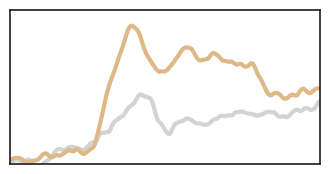

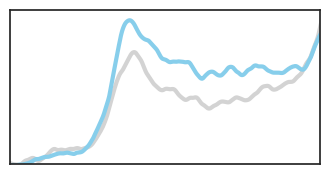

In [3]:
#####Fig.1
#Fig. 1
d14, d20 = pd.read_csv('data/processed/gel/Fig.1_N14.csv'), pd.read_csv('data/processed/gel/Fig.1_N20.csv')
sns.set_style('whitegrid')
sns.set_theme(style='ticks', font='Arial')
fig = plt.figure(figsize= (4,2))
ax = fig.add_subplot(1,1,1)
d = d14.copy()
IDs = list(d.columns)[2:]
cs = ['lightgrey','burlywood','grey','darkgoldenrod']

for i in range(0,2):
    s = d[IDs[i]].rolling(window=15, min_periods=1).mean()
    plt.plot(d['nt (estimated)'], s, linewidth = 3, c=cs[i])

ax.set_xlim(17,35)
ax.set_ylim(0,1000) #for N14
plt.gca().invert_xaxis()
ax.get_xaxis().set_visible(False), ax.get_yaxis().set_visible(False)
plt.show()

#####N20
fig = plt.figure(figsize= (4,2))
ax = fig.add_subplot(1,1,1)
d = d20.copy()
IDs = list(d.columns)[2:]
cs = ['lightgrey','skyblue','grey','steelblue']

for i in range(0,2):
    s = d[IDs[i]].rolling(window=12, min_periods=1).mean()
    plt.plot(d['nt (estimated)'], s, linewidth = 3, c=cs[i])

ax.set_xlim(24,50)
ax.set_ylim(0,2100) #for N20
plt.gca().invert_xaxis()
ax.get_xaxis().set_visible(False), ax.get_yaxis().set_visible(False)
plt.show()

#### C: Length distribution (average)

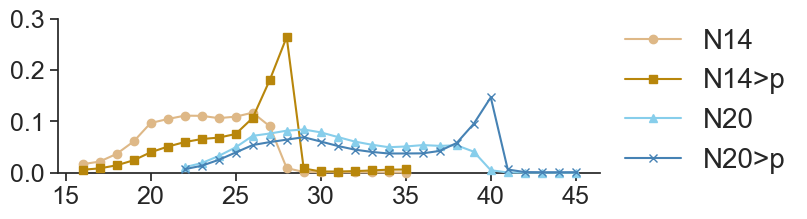

In [28]:
N14_counts = np.load(f'data/processed/length_distribution/N14_length_distribution_m15_M45.npy')
N14p_counts = np.load(f'data/processed/length_distribution/N14p_length_distribution_m15_M45.npy')
N20_counts = np.load(f'data/processed/length_distribution/N20_length_distribution_m21_M45.npy')
N20p_counts = np.load(f'data/processed/length_distribution/N20p_length_distribution_m21_M45.npy')

min14, max14 = 16,35
min20, max20 = 22,45

N14_counts2, N14p_counts2 = N14_counts[min14-15:max14-45], N14p_counts[min14-15:max14-45]
N20_counts2, N20p_counts2 = N20_counts[min20-21:], N20p_counts[min20-21:]

N14f, N14pf = N14_counts2/np.sum(N14_counts2, axis=0), N14p_counts2/np.sum(N14p_counts2, axis=0)
N20f, N20pf = N20_counts2/np.sum(N20_counts2, axis=0), N20p_counts2/np.sum(N20p_counts2, axis=0)

N14fave, N14pfave = np.average(N14f, axis=1), np.average(N14pf, axis=1)
N20fave, N20pfave = np.average(N20f, axis=1), np.average(N20pf, axis=1)

plt.rcParams['font.family'] = 'Arial'
sns.set_theme(style='ticks', font='Arial')
fig, ax = plt.subplots(figsize=(7, 2))
cols = ['burlywood', 'darkgoldenrod', 'skyblue', 'steelblue']
symbols = ['o', 's', '^', 'x']

ax.plot(np.arange(min14, max14+1), N14fave, label='N14', marker=symbols[0], markersize=6, color=cols[0], linestyle='-', clip_on=False, zorder=10)
ax.plot(np.arange(min14, max14+1), N14pfave, label='N14>p', marker=symbols[1], markersize=6, color=cols[1], linestyle='-', clip_on=False, zorder=11)
ax.plot(np.arange(min20, max20+1), N20fave, label='N20', marker=symbols[2], markersize=6, color=cols[2], linestyle='-', clip_on=False, zorder=12)
ax.plot(np.arange(min20, max20+1), N20pfave, label='N20>p', marker=symbols[3], markersize=6, color=cols[3], linestyle='-', clip_on=False, zorder=13)

ax.set_ylim(0, 0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis='both', which='major', labelsize=18)
ax.legend(loc='upper left', fontsize=20, bbox_to_anchor=(1.0, 1.1), frameon=False)
plt.show()

### **Fig　2.**
#### Base composition
- norm = {True, False}
- name = {N14, N14p, N20, N20p, N14_new, N14p_new, single_N14, single_N14p}

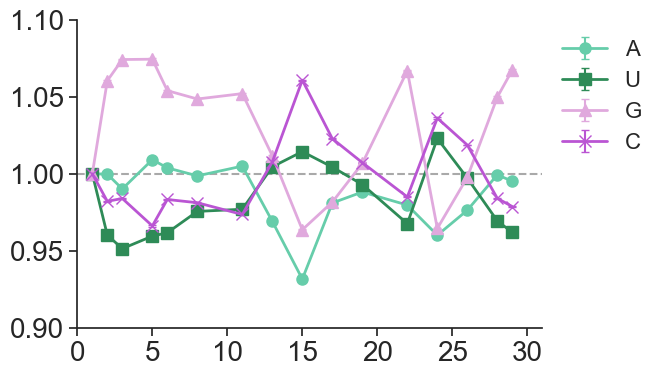

In [3]:
norm = True
name = 'N14p'

base_freqs_set = np.load(f'data/processed/base_composition/{name}_base_composition.npy')
Rs = round_labels(name)
if name in ['single_N14', 'single_N14p']:
    Rs = np.arange(len(Rs))
N = base_freqs_set.shape[0]


plt.rcParams['font.family'] = 'Arial'
sns.set_theme(style='ticks', font='Arial')

if norm:
    if name in ['N14', 'N14p', 'N20', 'N20p', 'N14p_new', 'N14_new']:
        freqs_set = base_freqs_set / base_freqs_set[:, :, 0][:, :, None]
    else:
        freqs_set = base_freqs_set / np.mean(base_freqs_set, axis=2)[:, :, None]
    mean_base_freqs = np.mean(freqs_set, axis=0)
    std_err = np.std(freqs_set, ddof=1, axis=0) / np.sqrt(N)
else:
    mean_base_freqs = np.mean(base_freqs_set, axis=0)
    std_err = np.std(base_freqs_set, ddof=1, axis=0) / np.sqrt(N)

if name in ['single_N14', 'single_N14p']:
    fig, ax = plt.subplots(figsize=(4, 4))
    linestyle = ''
else:
    fig, ax = plt.subplots(figsize=(6, 4))
    linestyle = '-'

cols = ['mediumaquamarine', 'seagreen', '#E0A9DD', 'mediumorchid']
bases = ['A', 'U', 'G', 'C']
for i, base in enumerate(bases):
    ax.errorbar(Rs, mean_base_freqs[i, :], yerr=std_err[i, :], label=f'{base}', color=cols[i], 
                marker=['o', 's', '^', 'x'][i], markersize=8, linestyle=linestyle, capsize=3, elinewidth=1.5, linewidth=2.0)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

if norm:
    ax.set_ylim(0.9, 1.1)
    ax.set_yticks(np.arange(0.9, 1.15, 0.05))
    #ax.set_ylabel('Relative Frequency', size=24)
    ax.axhline(y=1.0, color='darkgray', linestyle='--', linewidth=1.5)
else:
    ax.set_ylim(0.15, 0.35)
    ax.set_yticks(np.arange(0.15, 0.36, 0.05))
    #ax.set_ylabel('Frequency', size=24)

if name == 'single_N14' or name == 'single_N14p':
    ax.set_xlim(-0.5, 5.5)
    ax.set_xticks(Rs)
    ax.set_xticklabels(['1', '2', '3', '4a', '4b', '4c'])
    #ax.set_xlabel('Sample name', size=24)
else:
    ax.set_xlim(0, 31)
    ax.set_xticks(np.arange(0, 31, 5))
    #ax.set_xlabel('Round', size=24)
#ax.set_title(plotname(name), size=26)
ax.tick_params(axis='both', which='major', labelsize=20)
ax.legend(bbox_to_anchor=(1.0, 1), loc='upper left', fontsize=16, frameon=False)
# plt.tight_layout()

plt.show()

### **Fig　3.**
#### A: JS-divergence heatmap
- name = {N14, N14p. N20, N20p, N14_new, N14p_new, single_N14, single_N14p}
- vmin, vmax = float

p-value: 0.02120


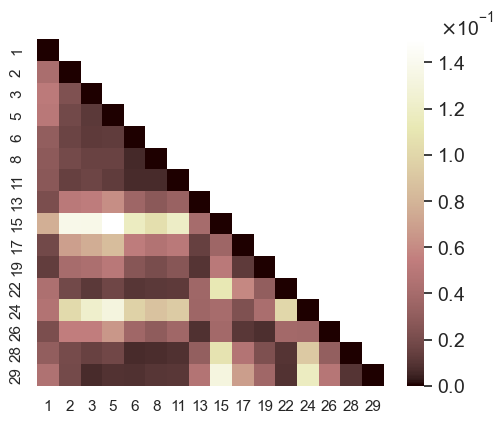

In [9]:
name = 'N14p'
vmin, vmax = 0, 0.15

k = 3
distance_matrix_set = np.load(f'data/processed/distance_matrix/{name}_k{k}_distance_matrix.npy')
Rs = round_labels(name)

sns.set_theme(style="white", font='Arial')
plt.rcParams['font.family'] = 'Arial'

cmap = sns.color_palette('pink', as_cmap=True)
fig, ax = plt.subplots(figsize=(6,4.5))

dm = np.mean(distance_matrix_set, axis=0)
p_val = permutation_test(dm, N=100000, order=1, side='right')
dm = mask_triangle(dm, upper=False)
sns.heatmap(dm, xticklabels=Rs, yticklabels=Rs, cmap=cmap, ax=ax, square=True, linewidths=0, linecolor=None,
            vmin=vmin, vmax=vmax, annot=False, fmt=".2f", annot_kws={"size": 8}, antialiased=False)

cbar = ax.collections[0].colorbar
cbar.ax.ticklabel_format(style='sci', axis='y', scilimits=(0,0), useMathText=True)
cbar.ax.tick_params(labelsize=14)
cbar.ax.yaxis.offsetText.set_position((5.0,0))
cbar.ax.yaxis.offsetText.set_fontsize(14)
#cbar.ax.set_ylabel('Jensen-Shannon Divergence (bits)', size=14, labelpad=10)

#fig.suptitle(plotname(name), size=16)
ax.tick_params(labelsize=11)

print(f'p-value: {p_val:.5f}')
if (p_val < 0.05) and (p_val >= 0.001):
    significance = '*'
elif (p_val < 0.001) and (p_val >= 0.0001):
    significance = '**'
elif p_val < 0.0001:
    significance = '***'
else:
    significance = ''

# if name in ['N14', 'N14p', 'N20', 'N20p', 'N14_new', 'N14p_new']:
#     ax.text(0.5, 1.0, f'$\it{{p}}$ = {p_val:.5f} {significance}',
#            size=14, ha='center', va='center', transform=ax.transAxes)
#     ax.set_xlabel('Rounds', size=14)
#     ax.set_ylabel('Rounds', size=14)
# else:
#     ax.set_xlabel('Sample name', size=14)
#     ax.set_ylabel('Sample name', size=14)
plt.show()

#### B: Box plot
- names = {N14, N14p, N20, N20p, N14_new, N14p_new}

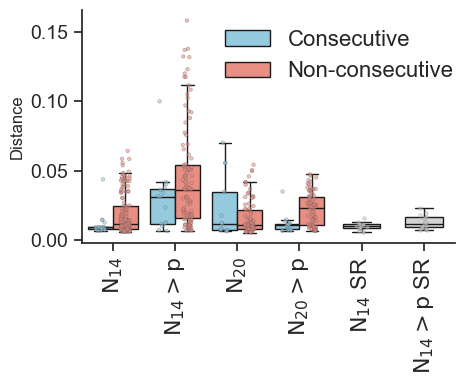

In [10]:
names = ['N14', 'N14p', 'N20', 'N20p']
k = 3

plt.rcParams['font.family'] = 'Arial'
sns.set_theme(style='ticks', font='Arial')
dists = []
labels = []
name_labels = []
for name in names:
    distance_matrix_set = np.load(f'data/processed/distance_matrix/{name}_k{k}_distance_matrix.npy')
    dm_mean = np.mean(distance_matrix_set, axis=0)
    max_val = np.max(dm_mean)
    for i in range(dm_mean.shape[0]):
        for j in range(i):
            if abs(i - j) == 1:
                labels.append('Consecutive')
            else:
                labels.append('Non-consecutive')
            name_labels.append(plotname(name))
            dists.append(dm_mean[i, j])

df_plot = DataFrame({'Distance': dists, 'Type': labels, 'Sample': name_labels})
fig, ax = plt.subplots(figsize=(5, 4))
sns.boxplot(data=df_plot, x='Sample', y='Distance', hue='Type',
            palette={'Consecutive': 'skyblue', 'Non-consecutive': 'salmon'},
            ax=ax,  fliersize=3, showfliers=False, linecolor='k')
sns.stripplot(data=df_plot, x='Sample', y='Distance', hue='Type',
            palette={'Consecutive': 'skyblue', 'Non-consecutive': 'salmon'},
            ax=ax, size = 2.5, alpha=0.5, linewidth=0.5, zorder=10, jitter=0.15, dodge=True, legend=0)

for i, name in enumerate(['single_N14', 'single_N14p']):
    distance_matrix_set = np.load(f'data/processed/distance_matrix/{name}_k{k}_distance_matrix.npy')
    dm_mean = np.mean(distance_matrix_set, axis=0)
    dists = np.triu(dm_mean, k=1)
    dists = dists[dists > 0].flatten()
    max_val = np.max(dm_mean)
    sns.boxplot(x=i+4, y=dists,color='lightgray', ax=ax, width=0.6, fliersize=3, showfliers=False, linecolor='k')
    sns.stripplot(x=i+4, y=dists,color='lightgray', 
                  size = 2.5, alpha=0.5, linewidth=0.5, zorder=10, jitter=0.1, dodge=True, legend=0)
ax.tick_params(axis='both', which='major', labelsize=14)
ax.set_xticklabels([plotname(name) for name in names + ['single_N14', 'single_N14p']], fontsize=16, rotation=90)
ax.set_xlabel(None)
#ax.set_ylabel('Jensen-Shannon\nDivergence (bits)', fontsize=16)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(fontsize=16, title_fontsize=16, bbox_to_anchor=(1.05, 1), loc='upper right', frameon=False)
plt.tight_layout()
plt.show()

#### D: Positional contribution
- names = {N14, N14p, N20p, N14p_new}
- end_from = {5, 3}

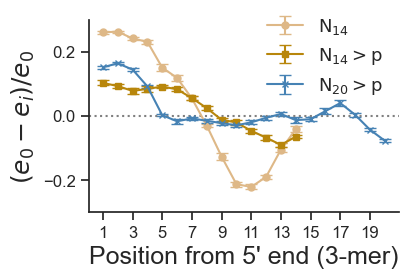

In [13]:
names = ['N14', 'N14p', 'N20p']
end_from = '5'


num_bases = 3
plt.rcParams['font.family'] = 'Arial'
sns.set_theme(style='ticks', font='Arial')
cols = ['burlywood', 'darkgoldenrod', 'steelblue']

if names[0] == 'N14p_new':
    cols = ['darkgoldenrod']
symbols = ['o', 's', 'x']

fig, ax = plt.subplots(figsize=(4, 2.5))

for i,name in enumerate(names):
    eval_indices = np.load(open(f'data/processed/pos_contribution/{name}_positional_contribution_{end_from}_n{num_bases}_k{k}.npy', 'rb'))
    pos_max = eval_indices.shape[1] - 1
    eval_indices_normal = (eval_indices[:, [0]] - eval_indices[:, 1:]) / eval_indices[:, [0]]
    std_error = np.std(eval_indices_normal, ddof=1, axis=0) / np.sqrt(eval_indices_normal.shape[0])
    mean_eval_indices = np.mean(eval_indices_normal, axis=0)

    if end_from == '5':
        x = np.arange(1, pos_max+1)
        y = mean_eval_indices
    else:
        x = np.arange(-pos_max, 0, 1)
        y = mean_eval_indices[::-1]
    ax.errorbar(x, y, yerr=std_error, label=f'{plotname(name)}',
                fmt = symbols[i], markersize=5, color=cols[i], capsize=4, linestyle='-')

if end_from == '5':
    ax.set_xticks(np.arange(1, pos_max+1,2))
else:
    ax.set_xticks(np.arange(-pos_max+1, 0, 2))
if end_from == '5':
    ax.set_xticklabels(np.arange(1, pos_max+1,2))
else:
    ax.set_xticklabels(np.arange(pos_max-1, 0, -2))

ax.axhline(0.0, color='gray', linestyle=':', linewidth=1.5)
ax.set_xlabel('Position from ' + ('5\'' if end_from=='5' else '3\'') + f' end ({num_bases}-mer)', fontsize=18)
ax.set_ylabel('$(e_{0}-e_{i})/e_{0}$', fontsize=18)
ax.set_ylim(-0.3, 0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis='both', which='major', labelsize=12)
if end_from == '5':
    ax.legend(loc='upper right', fontsize=13, bbox_to_anchor=(1.0, 1.1), frameon=False)
elif end_from == '3':
    ax.legend(loc='upper left', fontsize=13, bbox_to_anchor=(0, 1.1), frameon=False)
plt.show()

### **Fig　4.**
#### A: MFE JS-divergence heatmap
- name = {N14, N14p, N20, N20p, N14_new, N14p_new, single_N14, single_N14p}
- vmin, vmax = float

0.959180408195918


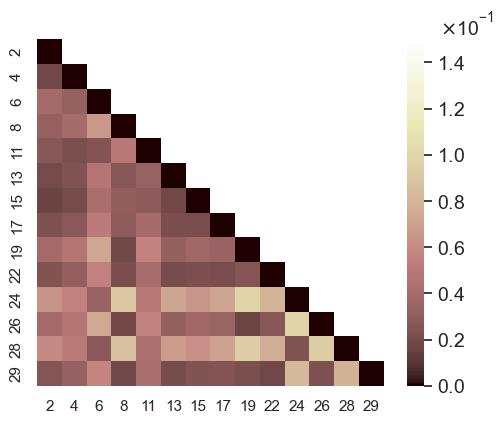

In [14]:
name = 'N20'
vmin, vmax = 0, 0.15

distance_matrix_set = np.load(f'data/processed/structure/{name}_distance_matrix.npy')
Rs = round_labels(name)

sns.set_theme(style="white", font='Arial')
plt.rcParams['font.family'] = 'Arial'

cmap = sns.color_palette('pink', as_cmap=True)
fig, ax = plt.subplots(figsize=(6,4.5))

dm = np.mean(distance_matrix_set, axis=0)
p_val = permutation_test(dm, N=100000, order=1, side='right')
dm = mask_triangle(dm, upper=False)
sns.heatmap(dm, xticklabels=Rs, yticklabels=Rs, cmap=cmap, ax=ax, square=True, linewidths=0,
            vmin=vmin, vmax=vmax, annot=False, fmt=".2f", annot_kws={"size": 8})

cbar = ax.collections[0].colorbar
cbar.ax.ticklabel_format(style='sci', axis='y', scilimits=(0,0), useMathText=True)
cbar.ax.tick_params(labelsize=14)
cbar.ax.yaxis.offsetText.set_position((5.0,0))
cbar.ax.yaxis.offsetText.set_fontsize(14)
#cbar.ax.set_ylabel('Jensen-Shannon Divergence (bits)', size=14, labelpad=10)

#fig.suptitle(plotname(name), size=16)
ax.tick_params(labelsize=11)
print(p_val)
if (p_val < 0.05) and (p_val >= 0.001):
    significance = '*'
elif (p_val < 0.001) and (p_val >= 0.0001):
    significance = '**'
elif p_val < 0.0001:
    significance = '***'
else:
    significance = ''

# if name in ['N14', 'N14p', 'N20', 'N20p', 'N14_new', 'N14p_new']:
#     ax.text(0.5, 1.0, f'$\it{{p}}$ = {p_val:.5f} {significance}',
#             size=14, ha='center', va='center', transform=ax.transAxes)
#     ax.set_xlabel('Rounds', size=14)
#     ax.set_ylabel('Rounds', size=14)
# else:
#     ax.set_xlabel('Sample name', size=14)
#     ax.set_ylabel('Sample name', size=14)
# plt.tight_layout()
plt.show()

#### B: Box plot
- name = {N14, N14p, N20, N20p, N14_new, N14p_new}

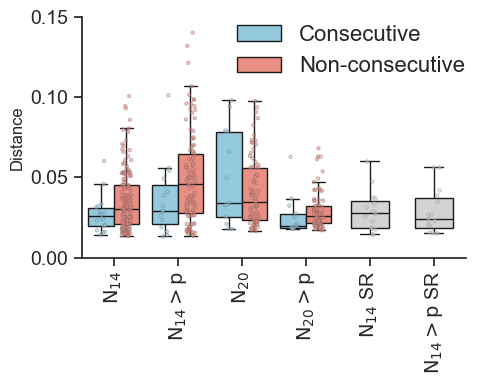

In [15]:
names = ['N14', 'N14p', 'N20', 'N20p']

plt.rcParams['font.family'] = 'Arial'
sns.set_theme(style='ticks', font='Arial')

dists = []
labels = []
name_labels = []
for name in names:
    distance_matrix_set = np.load(f'data/processed/structure/{name}_distance_matrix.npy')
    dm_mean = np.mean(distance_matrix_set, axis=0)
    max_val = np.max(dm_mean)
    for i in range(dm_mean.shape[0]):
        for j in range(i):
            if abs(i - j) == 1:
                labels.append('Consecutive')
            else:
                labels.append('Non-consecutive')
            name_labels.append(plotname(name))
            dists.append(dm_mean[i, j])

df_plot = DataFrame({'Distance': dists, 'Type': labels, 'Sample': name_labels})
fig, ax = plt.subplots(figsize=(5, 4))
# sns.boxplot(data=df_plot, x='Sample', y='Distance', hue='Type',
#             palette={'Consecutive': 'skyblue', 'Non-consecutive': 'salmon'},
#             ax=ax, width=0.6, fliersize=3)
sns.boxplot(data=df_plot, x='Sample', y='Distance', hue='Type',
            palette={'Consecutive': 'skyblue', 'Non-consecutive': 'salmon'}, #burlywood
            ax=ax,  fliersize=3, showfliers=False, linecolor='k') #width = 0.6
sns.stripplot(data=df_plot, x='Sample', y='Distance', hue='Type',
            palette={'Consecutive': 'skyblue', 'Non-consecutive': 'salmon'},
            ax=ax, size = 2.5, alpha=0.5, linewidth=0.5, zorder=10, jitter=0.15, dodge=True, legend=0)

for i, name in enumerate(['single_N14', 'single_N14p']):
    distance_matrix_set = np.load(f'data/processed/structure/{name}_distance_matrix.npy')
    dm_mean = np.mean(distance_matrix_set, axis=0)
    dists = np.triu(dm_mean, k=1)
    dists = dists[dists > 0].flatten()
    max_val = np.max(dm_mean)
    # sns.boxplot(x=i+4, y=dists, color='lightgray', ax=ax, width=0.6, fliersize=3)
    sns.boxplot(x=i+4, y=dists,color='lightgray', ax=ax, width=0.6, fliersize=3, showfliers=False, linecolor='k')
    sns.stripplot(x=i+4, y=dists,color='lightgray', 
                  size = 2.5, alpha=0.5, linewidth=0.5, zorder=10, jitter=0.1, dodge=True, legend=0)
ax.set_xticklabels([plotname(name) for name in names + ['single_N14', 'single_N14p']], fontsize=16, rotation=90)
ax.set_xlabel(None)
ax.set_yticks([0.00,0.05,0.10,0.15])
ax.tick_params(axis='both', which='major', labelsize=14)
#ax.set_ylabel('Jensen-Shannon\nDivergence (bits)', fontsize=16)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(fontsize=16, title_fontsize=16, bbox_to_anchor=(1.05, 1.05), loc='upper right', frameon=False)
plt.tight_layout()
plt.show()

### **Fig　5**
#### Complementarity enrichment
- name = {N14, N14p, N20p}
- k = {6, 8}
- terminal = {True, False}
- unpaired = {True, False}: if terminal is False, False

In [16]:
name = 'N14p'
k = 6
terminal = True
unpaired = True

if not terminal:
    unpaired = False

result = np.load(f'data/processed/overlap/{name}_overlap_summary_sub{k}_{k}_k{k}_n10_unpaired{unpaired}_terminal{terminal}.npz')
mat_nnz_set = result['mat_nnz']
Rs = result['Rs']

allow_diag = True
if name == 'N20p':
    p_val = permutation_test(mat_nnz_set.mean(axis=0), N=100000, order=1, side='left', pos='lower', allow_diag=allow_diag)
else:
    p_val = permutation_test(mat_nnz_set.mean(axis=0)[1:,1:], N=100000, order=1, side='left', pos='lower', allow_diag=allow_diag)
print(f'p-value: {p_val:.4f}')

p-value: 0.0474


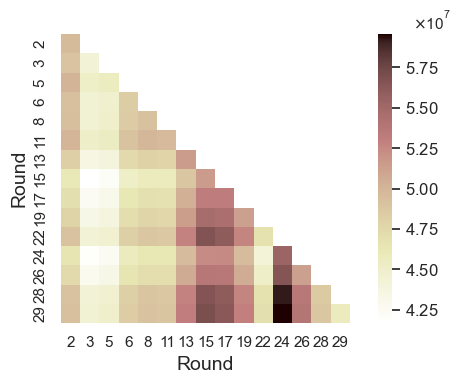

In [19]:
sns.set_theme(style="white")
fig, ax = plt.subplots(figsize=(6, 4))
cmap = sns.color_palette('pink_r', as_cmap=True)

if name == 'N20p': #初ラウンド (R2) から
    smat = np.mean(mat_nnz_set, axis=0)
    label = Rs
else: #初ラウンド (R1) を除く    
    smat = np.mean(mat_nnz_set, axis=0)[1:, 1:]
    label = Rs[1:]

smat = mask_triangle(smat, upper=False)
sns.heatmap(smat, xticklabels=label, yticklabels=label, cmap=cmap, ax=ax, square=True, linewidths=0,
            vmin=None, vmax=None, annot=False, fmt=".2f", annot_kws={"size": 8})
cbar = ax.collections[0].colorbar
cbar.ax.ticklabel_format(style='sci', axis='y', scilimits=(0,0), useMathText=True)
cbar.ax.tick_params(labelsize=12)
cbar.ax.yaxis.offsetText.set_position((5.0,0))
cbar.ax.yaxis.offsetText.set_fontsize(11)
ax.tick_params(labelsize=11)
ax.set_xlabel('Round', size=14), ax.set_ylabel('Round', size=14)
plt.tight_layout()
plt.show()

#### Box plot
- name = {N14, N14p, N20p}
- k = {6, 8}

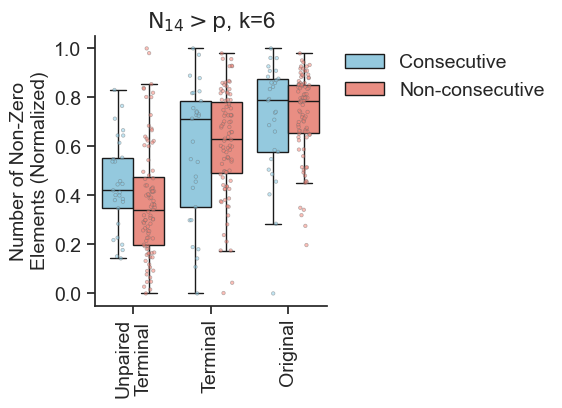

In [21]:
name = 'N14p'
k = 6
keys = [(False, False), (False, True), (True, True)]
names = ['Original', 'Terminal', 'Unpaired\nTerminal']

plt.rcParams['font.family'] = 'Arial'
sns.set_theme(style='ticks', font='Arial')

vals = []
labels = []
name_labels = []
for l, key in enumerate(keys):
    result = np.load(f'data/processed/overlap/{name}_overlap_summary_sub{k}_{k}_k{k}_n10_unpaired{key[0]}_terminal{key[1]}.npz')
    if name == 'N20p':
        smat = np.mean(mat_nnz_set, axis=0)
        label = Rs
    else:    
        smat = np.mean(mat_nnz_set, axis=0)[1:, 1:]
        label = Rs[1:]
    
    mat_nnz_set = result['mat_nnz']
    mat_nnz = mat_nnz_set.mean(axis=0)[1:, 1:]
    
    max_val = np.max(mat_nnz)
    min_val = np.min(mat_nnz)
    for i in range(mat_nnz.shape[0]):
        for j in range(i+1):
            if abs(i - j) <= 1:
                labels.append('Consecutive')
            else:
                labels.append('Non-consecutive')
            name_labels.append(names[l])
            vals.append((mat_nnz[i, j] - min_val) / (max_val - min_val) if max_val != min_val else 0)
            # vals.append(mat_nnz[i, j])

order = ['Unpaired\nTerminal', 'Terminal', 'Original']

df_plot = DataFrame({'Value': vals, 'Type': labels, 'Sample': name_labels})
fig, ax = plt.subplots(figsize=(3, 3.5))
sns.boxplot(data=df_plot, x='Sample', y='Value', hue='Type', order=order,
            palette={'Consecutive': 'skyblue', 'Non-consecutive': 'salmon'},
            ax=ax, fliersize=3, showfliers=False, linecolor='k') #width=0.6
sns.stripplot(data=df_plot, x='Sample', y='Value', hue='Type', order=order,
            palette={'Consecutive': 'skyblue', 'Non-consecutive': 'salmon'},
            ax=ax, size = 2.5, alpha=0.5, linewidth=0.5, zorder=10, jitter=0.15, dodge=True, legend=0)

ax.set_xticklabels(order, fontsize=16, rotation=90)
ax.set_title(f'{plotname(name)}, k={k}', size=16)
ax.set_xlabel(None)
ax.set_ylabel('Number of Non-Zero\nElements (Normalized)', fontsize=14)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(fontsize=14, title_fontsize=14, bbox_to_anchor=(1.0, 1.0), loc='upper left', frameon=False)
ax.tick_params(axis='both', which='major', labelsize=14)
plt.show()

### **Fig　6.**
#### B: Frequencies of XX(NNXX)n motifs

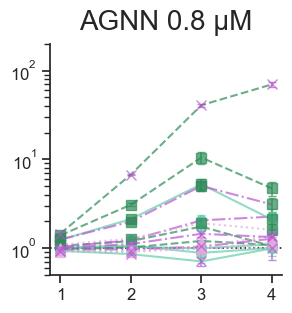

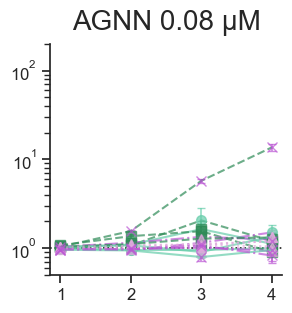

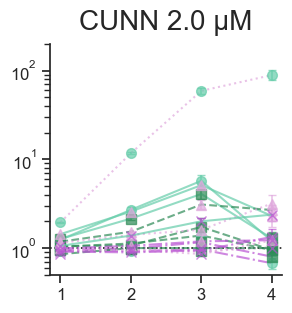

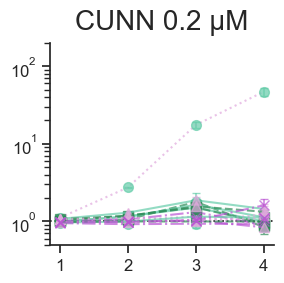

In [4]:
cols = ['mediumaquamarine', 'seagreen', '#E0A9DD', 'mediumorchid']
markers = ['o', 's', '^', 'x']
lines = ['-', '--', ':', '-.']
max_repeat = 4
min_repeat = 1
keys = ['AGNN 0.8 µM', 'AGNN 0.08 µM', 'CUNN 2.0 µM', 'CUNN 0.2 µM']
freqs_set = np.load(f'data/processed/2mer/2mer_repeat_freqs.npy')
N = freqs_set.shape[0]

mean_freqs_set = []
std_err_set = []
norm_inds = [4, 4, 5, 5]
for i in range(4):
    freqs = [freqs_set[m][i]/freqs_set[m][norm_inds[i]] for m in range(N)]
    mean_freqs = np.mean(freqs, axis=0)
    std_err = np.std(freqs, ddof=1, axis=0) / np.sqrt(N)
    mean_freqs_set.append(mean_freqs)
    std_err_set.append(std_err)

for i in range(4):
    fig, ax = plt.subplots(1, 1 , figsize=(3, 3))
    mean_freqs = mean_freqs_set[i]
    std_err = std_err_set[i]
    key = keys[i]
    for j in range(4):
        for k in range(4):
            ax.errorbar(range(min_repeat, max_repeat+1), mean_freqs[4*j+k, :],
                        yerr=std_err[4*j+k, :],
                        color=cols[k], linestyle=lines[k],
                        fmt=markers[j], markerfacecolor=cols[j], markeredgecolor=cols[j], ecolor=cols[j],
                        alpha=0.7, capsize=3, elinewidth=1.2, markersize=7)
    ax.axhline(y=1, color='k', linestyle=':', lw=1.2)
    ax.set_xticks(range(min_repeat, max_repeat+1))
    ax.set_yscale('log')
    ax.set_ylim(0.5, 200)
    # ax.set_xlabel('Number of repeats', size=18)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_title(key, fontsize=20, pad=10)
    ax.tick_params(axis='both', which='major', labelsize=12)

    ##### Legend
    # if ax.get_subplotspec().is_first_col():
    #     ax.set_ylabel('Relative\nfrequency (log)', size=18)
    # if ax.get_subplotspec().is_last_col():
    #     ### Null plot for legend
    #     for i in range(4):
    #         ax.plot([], [], color=cols[i], marker=markers[i], label=f'{['A', 'U', 'G', 'C'][i]}N', linestyle='None')
    #     for i in range(4):
    #             ax.plot([], [], color=cols[i], linestyle=lines[i], label=f'N{['A', 'U', 'G', 'C'][i]}')        
    #     ax.legend(bbox_to_anchor=(1.05, 1.05), loc='upper left', fontsize=14, frameon=False, borderaxespad=0)
#fig.text(0.5, 0.0, 'Number of repeats', ha='center', fontsize=18)
plt.tight_layout()
plt.show()

### **Fig　S2.**
#### Contamination probability
- after_blast = {True, False}
- name = {N14, N14p, N20, N20p}

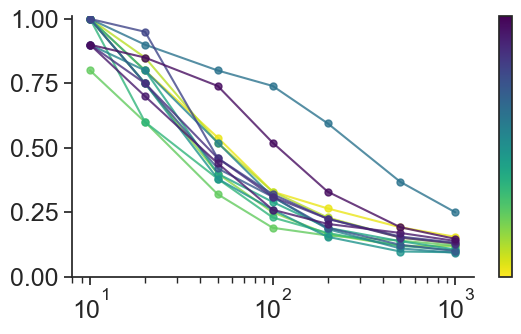

In [23]:
name = 'N20p'
after_blast = False

if after_blast:
    contamination_probs = np.load(f'data/processed/contamination_probs/{name}_contamination_probs_blast.npy')
else:
    contamination_probs = np.load(f'data/processed/contamination_probs/{name}_contamination_probs.npy')
Rs = round_labels(name)
top_nums = [10, 20, 50, 100, 200, 500, 1000]

plt.rcParams['font.family'] = 'Arial'
sns.set_theme(style='ticks', font='Arial')
cmap = plt.cm.viridis_r
#cols = cmap(np.linspace(0, 1, len(Rs)))
cols = cmap(np.linspace(0, 1, 30)) #colorbarを統一
fig, ax = plt.subplots(figsize=(6, 3.5))
for i, R in enumerate(Rs):
    ax.plot(top_nums, contamination_probs[i, :], label=R, color=cols[R-1], \
            marker='o', markersize=5, linestyle='-', alpha=0.8, linewidth=1.5)
ax.set_xscale('log')
ax.set_ylim(0, 1.01)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
#ax.set_title(plotname(name), size=13)
#ax.set_xlabel('Top N sequences', size=14)
#ax.set_ylabel('Contamination\nProbability', size=14)
ax.tick_params(axis='both', which='major', labelsize=18)
cbar = fig.colorbar(plt.cm.ScalarMappable(cmap=cmap), ax=ax)#, ticks=np.linspace(0, 1, 30)) #ticks=np.linspace(0, 1, len(Rs)))
#cbar.ax.set_yticklabels([str(R) for R in Rs], size=14)
#cbar.ax.set_ylabel('Round', labelpad=5, size=14)
cbar.set_ticks([])
plt.tight_layout()
plt.show()

### **Fig　S3.**
#### Cumulative explained variance of PCA for k-mer frequency vectors

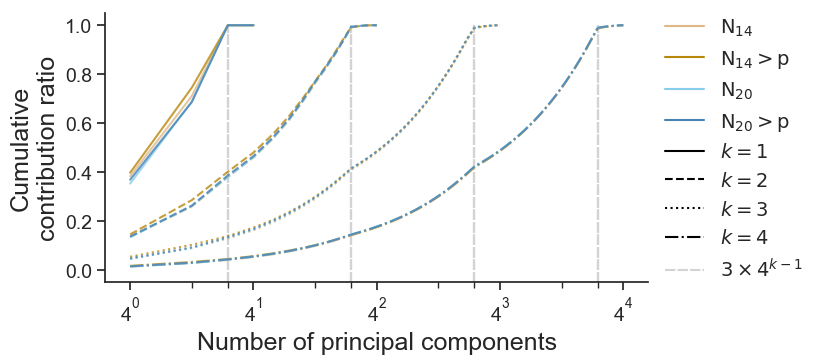

In [24]:
names = ['N14', 'N14p', 'N20', 'N20p']
cols = ['burlywood', 'darkgoldenrod', 'skyblue', 'steelblue']
ks = np.arange(1, 5)
ccr_set = np.load('data/processed/pca_contribution_ratio/pca_contribution_ratios.npy', allow_pickle=True)
plt.rcParams['font.family'] = 'Arial'
sns.set_theme(style='ticks', font='Arial')

fig, ax = plt.subplots(figsize=(7, 3.5))
for k in ks:
    for i, name, ccrs in zip(list(range(4)), names, ccr_set[(k-1)*len(names):k*len(names)]):
        ax.plot(np.arange(1, len(ccrs)+1), ccrs, color=cols[i],
                linestyle=['-', '--', ':', '-.'][k-1], linewidth=1.5, alpha=0.8)
        ax.vlines(x=3*4**(k-1), color='lightgray', linestyle=(0, (5, 1)), linewidth=1.5, ymin=-0.1, ymax=1, zorder=1)

### Null plot for reference
for i,name in enumerate(names):
    ax.plot([], [], color=cols[i], label=f'{plotname(name)}')
ax.plot([], [], color='black', linestyle='-', label='$k=1$', linewidth=1.5)
ax.plot([], [], color='black', linestyle='--', label='$k=2$', linewidth=1.5)
ax.plot([], [], color='black', linestyle=':', label='$k=3$', linewidth=1.5)
ax.plot([], [], color='black', linestyle='-.', label='$k=4$', linewidth=1.5)
ax.plot([], [], color='lightgray', linestyle=(0, (5, 1)), label='$3\\times4^{k-1}$', linewidth=1.5)
### End of null plot

ax.set_xlabel('Number of principal components', size=18)
ax.set_ylabel('Cumulative\ncontribution ratio', size=18)
ax.tick_params(axis='both', which='major', labelsize=14)
ax.set_xscale('log', base=4)
ax.set_ylim(-0.05, 1.05)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(fontsize=14, loc='upper left', bbox_to_anchor=(1, 1.05), frameon=False)
plt.show()

### **Fig　S4.**
#### χ2 dist vs Squared Mahalanobis dist
- name = {N14, N14p, N20, N20p}
- k ∈ (1, 4)
- max_val = int, e.g. {k=1: 20, k=2: 50, k=3: 150, k=4: 500}
- min_val = int, e.g. {k=1: -1, k=2: 0, k=3: 10, k=4: 50}



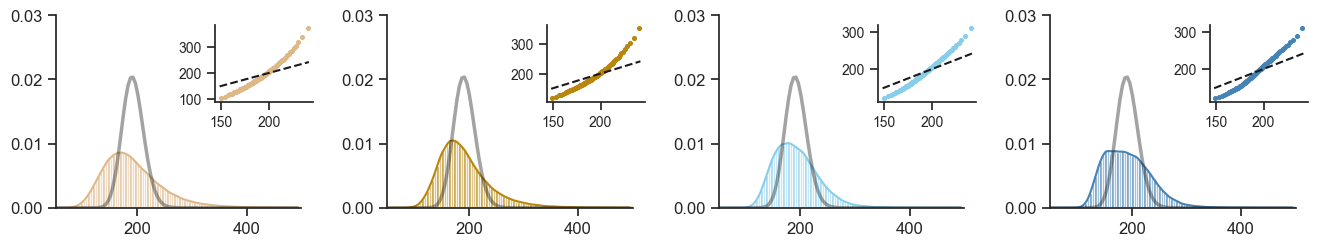

In [25]:
#Fig. S11 Modified
k = 4
name = 'N20'
#max_val = int, e.g. {k=1: 20, k=2: 50, k=3: 150, k=4: 500}
#min_val = int, e.g. {k=1: -1, k=2: 0, k=3: 10, k=4: 50}
max_val, min_val = 500, 50

names = ['N14', 'N14p', 'N20', 'N20p']
#inds = names.index(name)
mhdists_list = np.load(f'data/processed/mahalanobis/mhdists_list_k{k}.npy', allow_pickle=True)
counts_list = np.load(f'data/processed/mahalanobis/counts_list_k{k}.npy', allow_pickle=True)

plt.rcParams['font.family'] = 'Arial'
sns.set_theme(style='ticks', font='Arial')

fig = plt.figure(figsize=(16, 2.5))
plt.subplots_adjust(wspace = 0.35)
cols = ['burlywood', 'darkgoldenrod', 'skyblue', 'steelblue']
#fig, ax = plt.subplots(figsize=(6,4))
for i, name in enumerate(names):
    ax = plt.subplot(1,4,i+1)
    mhdists = mhdists_list[i]
    counts = counts_list[i]
    bins = np.arange(min_val, max_val, (max_val - min_val) / 100)
    mhdist_hist, bin_edges = np.histogram(mhdists, bins=bins, weights=counts, density=True)
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
    ax.bar(bin_centers, mhdist_hist, width=bin_edges[1]-bin_edges[0], color=cols[i], alpha=0.8,
           label='Sample data')
    kde = stats.gaussian_kde(mhdists, weights=counts)
    x_eval = np.linspace(min_val, max_val, 1000)
    ax.plot(x_eval, kde(x_eval), '-', lw=1.5, label='KDE', color=cols[i])
    ax.plot(bin_centers, chi2.pdf(bin_centers, df=3*4**(k-1)), 'k-', lw=2.5, alpha=0.4, label=f'$\\chi^2$ distribution (df={3*4**(k-1)})')
    #ax.set_xlabel('Squared Mahalanobis Distance', fontsize=18)
    #ax.set_ylabel('Density', fontsize=18)
    ax.set_xlim(min_val, max_val)
    ax.set_ylim(0, np.ceil((np.max(mhdist_hist) + 0.0115)*100)/100)
    ax.spines['top'].set_visible(False), ax.spines['right'].set_visible(False)
    #ax.set_title(plotname(names[i]), fontsize=24, pad=10)
    #ax.legend(fontsize=14, bbox_to_anchor=(1.05, 0.4), loc='upper right', frameon=False)
    ax.tick_params(axis='both', which='major', labelsize=12)

    # QQ-plot on the same figure
    ax2 = ax.inset_axes([0.65, 0.55, 0.4, 0.4])
    sample_quantiles = np.percentile(mhdists, np.linspace(1, 99, 100))
    theoretical_quantiles = chi2.ppf(np.linspace(0.01, 0.99, 100), df=3*4**(k-1))
    ax2.scatter(theoretical_quantiles, sample_quantiles, color=cols[i], s=7)
    min_val_2 = max(theoretical_quantiles.min(), sample_quantiles.min()) - 1
    max_val_2 = min(theoretical_quantiles.max(), sample_quantiles.max()) + 1
    ax2.plot([min_val_2, max_val_2], [min_val_2, max_val_2], 'k--', lw=1.5)
    #ax2.set_xlabel('Theoretical Quantiles', fontsize=12)
    #ax2.set_ylabel('Sample Quantiles', fontsize=12)
    ax2.tick_params(axis='both', which='major', labelsize=10)
    #ax2.text(0.5, 0.95, 'QQ-plot', fontsize=14, ha='center', transform=ax2.transAxes)
    ax2.spines['top'].set_visible(False), ax2.spines['right'].set_visible(False)
    # ax2.set_xlim(np.floor(sample_quantiles.min()), np.ceil(sample_quantiles.max()))
plt.show()

### **Fig　S6.**
#### Length distribution
- name = {N14, N14p, N20, N20p, N14_new, N14p_new, single_N14, single_N14p}
- min_len = {  
  N14, N14_new, single_N14, N14p, N14p_new, single_N14p: ∈ (15, 45)  
  N20, N20p: ∈ (21, 45)  
  }
- max_len = {  
  N14, N14_new, single_N14, N14p, N14p_new, single_N14p: ∈ (15, 45)  
  N20, N20p: ∈ (21, 45)  
  }

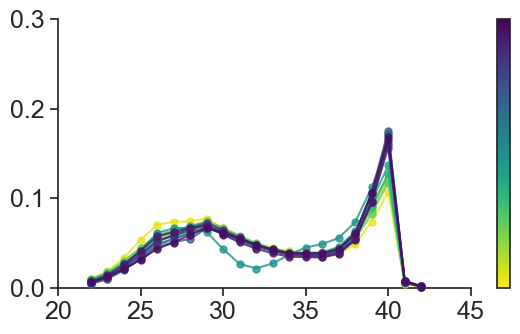

In [13]:
name = 'N20p'
min14, max14 = 16,35
min20, max20 = 22,42

N14_counts = np.load(f'data/processed/length_distribution/N14_length_distribution_m15_M45.npy')
N14p_counts = np.load(f'data/processed/length_distribution/N14p_length_distribution_m15_M45.npy')
N20_counts = np.load(f'data/processed/length_distribution/N20_length_distribution_m21_M45.npy')
N20p_counts = np.load(f'data/processed/length_distribution/N20p_length_distribution_m21_M45.npy')

N14_counts2, N14p_counts2 = N14_counts[min14-15:max14-45], N14p_counts[min14-15:max14-45]
N20_counts2, N20p_counts2 = N20_counts[min20-21:max20-45], N20p_counts[min20-21:max20-45]

N14f, N14pf = N14_counts2/np.sum(N14_counts2, axis=0), N14p_counts2/np.sum(N14p_counts2, axis=0)
N20f, N20pf = N20_counts2/np.sum(N20_counts2, axis=0), N20p_counts2/np.sum(N20p_counts2, axis=0)


Rs = round_labels(name)
if name == 'N14':
    fs = N14f
elif name == 'N14p':
    fs = N14pf
elif name == 'N20':
    fs = N20f
elif name == 'N20p':
    fs = N20pf
    
if name in ['N14', 'N14p']:
    x = np.arange(min14, max14+1)
else:
    x = np.arange(min20, max20+1)

plt.rcParams['font.family'] = 'Arial'
sns.set_theme(style='ticks', font='Arial')

cmap = plt.cm.viridis_r
cols = cmap(np.linspace(0, 1, 30))
fig, ax = plt.subplots(figsize=(6, 3.5))
for i, R in enumerate(Rs):
    ax.plot(x, fs[:,i], label=R, color=cols[R-1], \
            marker='o', markersize=5, linestyle='-', alpha=0.8, linewidth=1.5, clip_on=False, zorder=10)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_ylim(0,0.3)
if name in ['N14', 'N14p']:
    ax.set_xlim(15,35)
else:
    ax.set_xlim(20,45)
ax.set_yticks([0,0.1,0.2,0.3])
ax.tick_params(axis='both', which='major', labelsize=18)
cbar = fig.colorbar(plt.cm.ScalarMappable(cmap=cmap), ax=ax)
cbar.set_ticks([])
plt.tight_layout()
plt.show()

### **Fig　S7.**
#### Count of identical seqs from two rounds
- name = {N14, N14p, N20, N20p, N14_new, N14p_new}

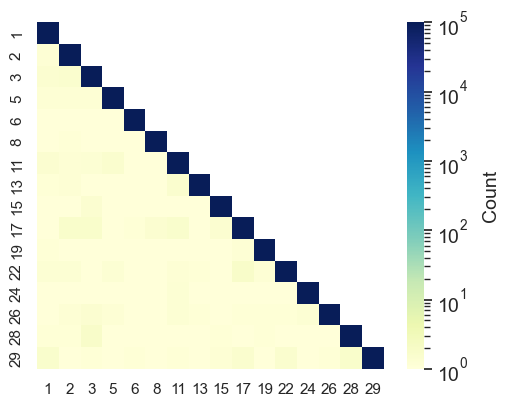

In [32]:
name = 'N14p'

key = 'genotype'
plt.rcParams['font.family'] = 'Arial'
sns.set_theme(style="white", font='Arial')
mat = np.load(f'data/processed/geno_similarity/{name}_{key}_matrix_set.npy').mean(axis=0)
Rs = round_labels(name)

fig, ax = plt.subplots(figsize=(6, 4.5))
cmap = sns.color_palette("YlGnBu", as_cmap=True)
mat = mask_triangle(mat, upper=False)
sns.heatmap(mat, xticklabels=Rs, yticklabels=Rs, cmap=cmap, ax=ax, square=True, linewidths=0,
            vmin=None, vmax=None, annot=False, fmt=".2f", annot_kws={"size": 8}, norm=mcolors.LogNorm(vmin=1.0, vmax=1E5))

cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=14)
cbar.ax.yaxis.offsetText.set_position((5.0,0))
cbar.ax.yaxis.offsetText.set_fontsize(11)
cbar.ax.set_ylabel('Count', size=14, labelpad=10)

#fig.suptitle(f'{plotname(name)}', size=16)
ax.tick_params(labelsize=11)
#ax.set_xlabel('Round', size=14)
#ax.set_ylabel('Round', size=14)
# plt.tight_layout()
plt.show()

### **Fig　S8.**
#### Population entropy
- name = {N14, N14p, N20, N20p, N14_new, N14p_new}

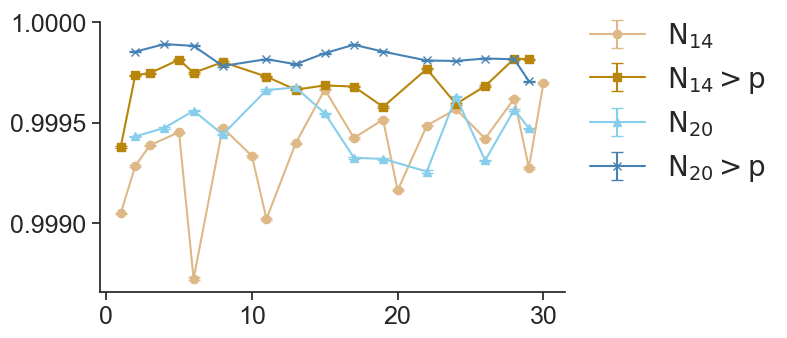

In [33]:
names = ['N14', 'N14p', 'N20', 'N20p']

plt.rcParams['font.family'] = 'Arial'
sns.set_theme(style='ticks', font='Arial')
fig, ax = plt.subplots(figsize=(6, 3.5))
cols = ['burlywood', 'darkgoldenrod', 'skyblue', 'steelblue']
symbols = ['o', 's', '^', 'x']
for i,name in enumerate(names):
    Rs = round_labels(name)
    entropy_values_set = np.load(f'data/processed/entropy/{name}_entropy.npy')
    mean_entropy_values = np.mean(entropy_values_set, axis=0)
    std_err = np.std(entropy_values_set, ddof=1, axis=0) / np.sqrt(entropy_values_set.shape[0])
    ax.errorbar(Rs, mean_entropy_values, yerr=std_err, label=plotname(name), \
                marker=symbols[i], markersize=6, color=cols[i], capsize=4, linestyle='-')
#ax.set_xlabel('Round', size=18)
#ax.set_ylabel('Population Entropy', size=18)
ax.set_ylim(None, 1.00)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis='both', which='major', labelsize=18)
#ax.set_ylim(0,1.05)
ax.legend(loc='upper left', fontsize=20, bbox_to_anchor=(1.0, 1.1), frameon=False)
# plt.tight_layout()
plt.show()

### **Fig　S9.**
#### kmer contribution
- names = {N14, N14p, N20p, N14p_new}

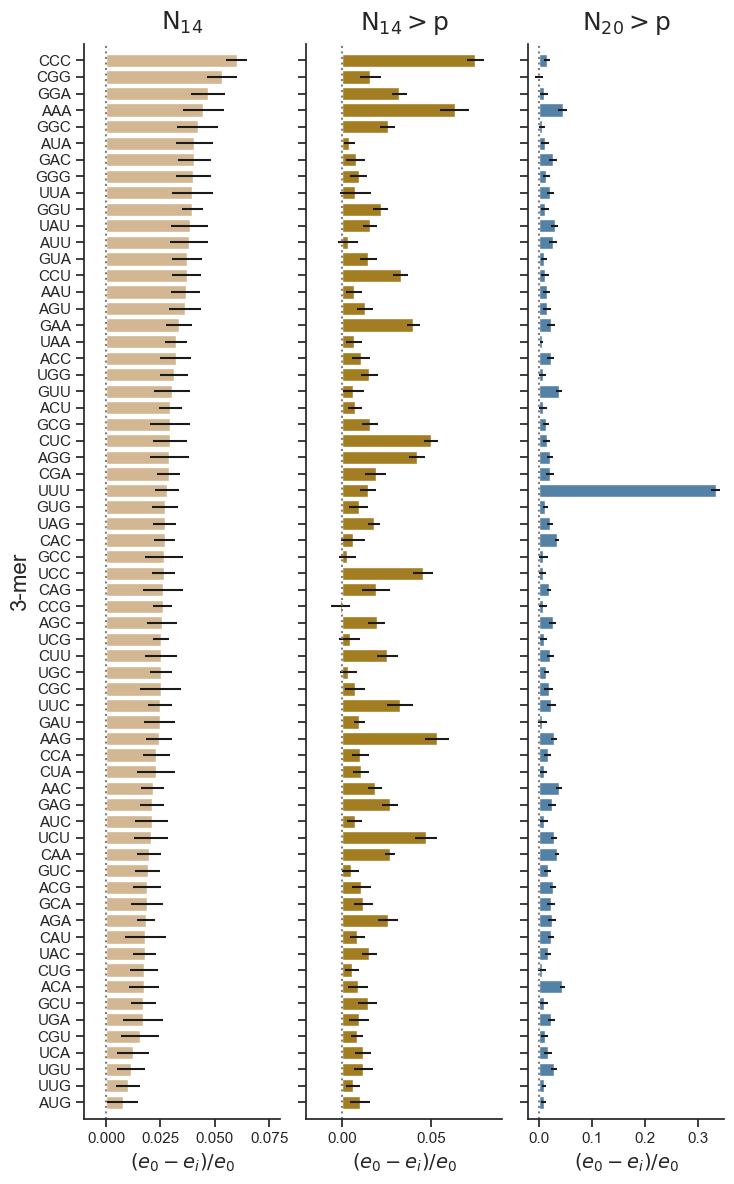

In [34]:
names = ['N14', 'N14p', 'N20p']

plt.rcParams['font.family'] = 'Arial'
sns.set_theme(style='ticks', font='Arial')
mean_contribution_list = []
std_error_list = []
for name in names:
    dists = np.load(f'data/processed/kmer_contribution/{name}_kmer_contribution.npy')
    contribution_ratios = (dists[:, [0]] - dists[:, 1:]) / dists[:, [0]]
    mean_contribution = np.mean(contribution_ratios, axis=0)
    std_error = np.std(contribution_ratios, ddof=1, axis=0) / np.sqrt(contribution_ratios.shape[0])
    mean_contribution_list.append(mean_contribution)
    std_error_list.append(std_error)

cols = ['burlywood', 'darkgoldenrod', 'steelblue']
inds = np.argsort(mean_contribution_list[0])[::-1]
fig, axs = plt.subplots(1, len(names), figsize=(2.5 * len(names), 12))
for ax, name, mean_contribution, std_error, i in zip(axs.flatten(), names, mean_contribution_list, std_error_list, list(range(3))):
    kmers = make_kmers(['A', 'U', 'G', 'C'], 3)
    sns.barplot(x=mean_contribution[inds], y=[kmers[i] for i in inds], xerr=std_error[inds],
                color=cols[i], alpha=1, capsize=3, ax=ax)
    if ax.get_subplotspec().is_first_col():
        ax.set_ylabel('3-mer', fontsize=16)
    else:
        ax.set_yticklabels([])
    ax.set_xlabel('$(e_{0}-e_{i})/e_{0}$', fontsize=14)
    ax.set_xlim(np.floor((np.min(mean_contribution)-0.01)*100)/100, np.ceil((np.max(mean_contribution)+0.01)*100)/100)
    ax.set_ylim(len(kmers), -1)
    ax.axvline(0.0, color='gray', linestyle=':', linewidth=1.5)
    ax.set_title(plotname(name), size=18, pad=10)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()

### **Fig S10.**
#### Base pair probability
- name = {N14, N14p, N20, N20p, N14_new, N14p_new}

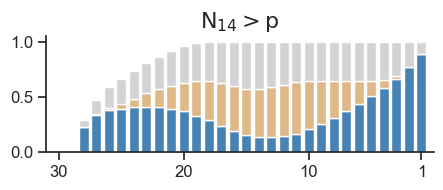

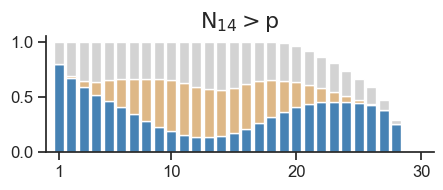

In [35]:
name = 'N14p'

N = 10
bp_freqs_set_3 = np.load(f'data/processed/base_pairing/{name}_bp_freqs_3.npy')
bp_freqs_set_5 = np.load(f'data/processed/base_pairing/{name}_bp_freqs_5.npy')
if name in ['N20', 'N20p']:
    min_len = 25
    max_len = 45
else:
    min_len = 18
    max_len = 30

for key in ['3', '5']:
    if key == '3':
        bp_freqs_set = bp_freqs_set_3
    else:
        bp_freqs_set = bp_freqs_set_5
    mean_bp_freqs = np.mean(bp_freqs_set, axis=0)
    std_err_bp_freqs = np.std(bp_freqs_set, ddof=1, axis=0) / np.sqrt(N)
    positions = np.arange(1, max_len+1)
    bottom = np.zeros(max_len)
    cols = ['steelblue', 'burlywood', 'lightgray']

    sns.set_theme(style='ticks')
    plt.rcParams['font.family'] = 'Arial'
    fig, ax = plt.subplots(figsize=(5, 1.5))
    for i, label in enumerate(['Unpaired (End)', 'Unpaired (Internal)', 'Paired']):
        ax.bar(positions, mean_bp_freqs[i, :], bottom=bottom, color=cols[i], label=label, alpha=1, width=0.8)
        bottom += mean_bp_freqs[i, :]    
    #ax.set_xlabel(f'Nucleotide Position from {key}\' end (nt)', fontsize=14)
    #ax.set_ylabel('Probability', fontsize=14)
    ticks = [1] + list(np.arange(10, max_len+1, 10))
    if key == '5':
        ax.set_xticks(ticks)
        ax.set_xticklabels(ticks)
        ax.set_xlim(0, max_len+1)
    elif key == '3':
        ax.set_xticks(list(np.arange(max_len-10+1, 0, -10))[::-1] + [max_len])
        ax.set_xticklabels(ticks[::-1])
        ax.set_xlim(0, max_len+1)
    ax.tick_params(axis='both', which='major', labelsize=12)
    # ax.set_xticks(np.arange(1, max_len+1, 2))
    ax.set_title(plotname(name), fontsize=16)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    #ax.legend(loc='upper left', bbox_to_anchor=(1, 1), fontsize=12, title_fontsize=11, frameon=False)
    # plt.tight_layout()
    plt.show()

### **Fig S13.**
#### MFE distribution of 22-mer and AG(NNAG)5, CU(NNCU)5

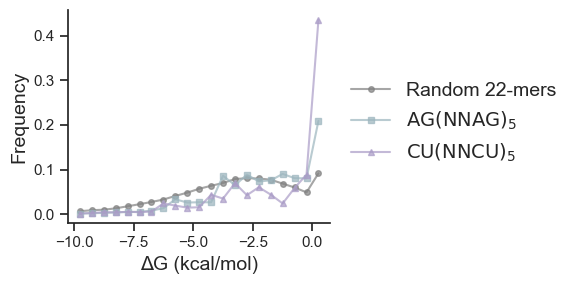

In [7]:
result = np.load(f'data/processed/overlap/mfe_distribution_fixed_seqs.npz')
bin_centers = result['bin_centers']
freqs_random = result['freqs_random']
freqs_fixed1 = result['freqs_fixed1']
freqs_fixed2 = result['freqs_fixed2']

plt.rcParams['font.family'] = 'Arial'
sns.set_theme(style='ticks', font='Arial')

cs = ['grey', '#9CB5BE', '#AA9CC7']

fig, ax = plt.subplots(figsize=(6, 3))


ax.plot(bin_centers, freqs_random, color=cs[0], label='Random 22-mers', linewidth=1.5, marker='o', markersize=4, alpha=0.7)
ax.plot(bin_centers, freqs_fixed1, color=cs[1], label='$\mathrm{AG(NNAG)_{5}}$', linewidth=1.5, marker='s', markersize=4, alpha=0.7)
ax.plot(bin_centers, freqs_fixed2, color=cs[2], label='$\mathrm{CU(NNCU)_{5}}$', linewidth=1.5, marker='^', markersize=4, alpha=0.7)
ax.set_xlabel('ΔG (kcal/mol)', fontsize=14)
ax.set_ylabel('Frequency', fontsize=14)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
#ax.legend(fontsize=14, title_fontsize=14, frameon=False)
ax.legend(bbox_to_anchor=(1.05, 0.7), loc='upper left', fontsize=14, frameon=False, borderaxespad=0)
#ax.set_yscale('log')
plt.tight_layout()
plt.show()